# 06 — Day 6 Evaluation: Combining Augmented HuBERT L12 with Day 1's PCA / Session-Fusion

**Standalone**, same pattern as `04_evaluate_trillsson.ipynb`, `05_evaluate_hubert_augmented.ipynb`, and `permutation_test_hubert_layer12.ipynb` — duplicated helper functions, no shared imports.

**What this tests:** Day 1's PCA and session-level fusion (`02_train_evaluate.ipynb` section 11) were both tuned against the *un-augmented* HuBERT layer 12 embedding. Day 5 then found that speed-perturbation training augmentation on top of plain HuBERT L12 improved AUC from 0.611 to 0.639 (CI [0.576, 0.705]). This notebook re-tests PCA and session-fusion **on top of the augmented base** — never assuming a technique that helped (or didn't) on the old base will behave the same way on the new one — then, if warranted, combines them, re-verifies every leakage assertion, and runs the one permutation test this project reserves for a finalized pipeline.

**Four configurations, tested in order, same discipline as every other day (one variable at a time before combining):**
1. Augmented HuBERT L12 alone — reproduced here as a sanity check (should match Day 5's 0.639).
2. Augmented HuBERT L12 + PCA (isolated).
3. Augmented HuBERT L12 + session-level fusion (isolated).
4. Augmented HuBERT L12 + session-level fusion + PCA (combined) — built regardless of what #2/#3 show, since this notebook runs top-to-bottom in one Kaggle pass and can't branch on its own mid-run results, but interpreted with an explicit caveat below: if neither #2 nor #3 helped on its own, a win for #4 is a redundancy-shopping risk, not a confirmed synergy.

Whichever of the four scores highest is **automatically selected** for the one permutation test this notebook runs (Section 7) — see Section 5 for the exact rule and its stated limitation.

**The augmentation-leakage rule, unchanged from Day 5 and re-verified here (Section 6):** augmented copies only ever enrich a *training* pool. Whenever a participant is scored — as the outer test fold, or as an inner-CV validation fold — only their original, unperturbed recordings are used. This applies identically whether the grain is one recording or one fused session.

**Inputs needed (Kaggle "Add Input") — the same 3 as `05_evaluate_hubert_augmented.ipynb`:**
1. The **`Fatigue_data`** dataset — for `labels.csv`.
2. **Day 3's `01_features.ipynb`** output — for `hubert_base_all_layers.parquet` (original/unperturbed layer-12 embeddings).
3. **`05_features_hubert_augmented.ipynb`**'s output — for `hubert_layer12_speed_augmented.parquet` (the 0.9x/1.1x embeddings).

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_SEED = 42
LAYER = 12

LABELS_CSV = next(Path("/kaggle/input").rglob("labels.csv"))
HUBERT_ALL_LAYERS_PARQUET = next(Path("/kaggle/input").rglob("hubert_base_all_layers.parquet"))
AUGMENTED_PARQUET = next(Path("/kaggle/input").rglob("hubert_layer12_speed_augmented.parquet"))

print(f"LABELS_CSV                = {LABELS_CSV}")
print(f"HUBERT_ALL_LAYERS_PARQUET = {HUBERT_ALL_LAYERS_PARQUET}")
print(f"AUGMENTED_PARQUET         = {AUGMENTED_PARQUET}")

LABELS_CSV                = /kaggle/input/datasets/tapudatta/fatigue-data/project_data/labels.csv
HUBERT_ALL_LAYERS_PARQUET = /kaggle/input/notebooks/tappu1/notebook1-day3/features/hubert_base_all_layers.parquet
AUGMENTED_PARQUET         = /kaggle/input/notebooks/tapudatta/day5-aug-features/features/hubert_layer12_speed_augmented.parquet


## 1. Combine Original + Augmented Embeddings

Identical to `05_evaluate_hubert_augmented.ipynb` section 1 — pulls layer 12 out of Day 3's all-layers file (tagged `speed_factor=1.0`), concatenates with the 0.9x/1.1x augmented embeddings. Kept at the *recording* grain here (not collapsed to just `X`/`y`/`groups` like Day 5 did) because Section 4's session-fusion variant needs `session_number` and `activity_type` to know which rows to concatenate.

In [2]:
labels = pd.read_csv(LABELS_CSV)
hubert_all_layers = pd.read_parquet(HUBERT_ALL_LAYERS_PARQUET)
augmented = pd.read_parquet(AUGMENTED_PARQUET)

layer_cols = [c for c in hubert_all_layers.columns if c.startswith(f"layer{LAYER}_emb_")]
assert len(layer_cols) == 1536, f"expected 1536 layer-{LAYER} columns, got {len(layer_cols)}"
original_layer12 = hubert_all_layers[["filename"] + layer_cols].copy()
original_layer12.columns = ["filename"] + [f"emb_{i}" for i in range(1536)]
original_layer12["speed_factor"] = 1.0

augmented = augmented.rename(columns={"source_filename": "filename"})

combined_emb = pd.concat([original_layer12, augmented], ignore_index=True, sort=False)
assert len(combined_emb) == 280 * 3, f"expected 840 combined rows, got {len(combined_emb)}"

df_aug = labels.merge(combined_emb, on="filename", how="inner").reset_index(drop=True)
assert len(df_aug) == 280 * 3, f"expected 840 rows after merge, got {len(df_aug)}"

LABEL_MAP = {"non_fatigued": 0, "fatigued": 1}
df_aug["y"] = df_aug["label"].map(LABEL_MAP)
assert df_aug["y"].isna().sum() == 0
df_aug["is_original"] = df_aug["speed_factor"] == 1.0

# Re-check the join didn't silently create a filename with more than one participant_id
# across its speed variants -- this would mean a bug in how the augmented file was built.
per_filename_participants = df_aug.groupby("filename")["participant_id"].nunique()
assert (per_filename_participants == 1).all(), \
    "a filename maps to more than one participant_id across its speed variants -- bug"

emb_cols = [c for c in df_aug.columns if c.startswith("emb_")]
X = df_aug[emb_cols].to_numpy()
y = df_aug["y"].to_numpy()
groups = df_aug["participant_id"].to_numpy()
is_original = df_aug["is_original"].to_numpy()

print(f"Total rows: {len(df_aug)} (280 original + 560 augmented)")
print(f"X: {X.shape}, original rows: {is_original.sum()}, augmented rows: {(~is_original).sum()}")
print("Checked: every recording's original + augmented copies share exactly one participant_id.")

Total rows: 840 (280 original + 560 augmented)
X: (840, 1536), original rows: 280, augmented rows: 560
Checked: every recording's original + augmented copies share exactly one participant_id.


## 2. Shared Candidates, Pipelines & Augmentation-Aware Nested CV

Reusable across all four configurations below, so each is exactly one line to run.

- **`build_pipeline_pca`** — same as `02_train_evaluate.ipynb` section 11a: scaler, optional PCA, classifier. `pca_components=None` reproduces the plain (no-PCA) pipeline exactly.
- **`make_candidates_plain`** — the original 10 candidates (2 model types × 5 `C` values), no PCA. Used for configurations #1 (baseline reproduction) and #3 (session-fusion alone), which change the input features but not the candidate set.
- **`make_candidates_pca`** — 30 candidates (2 model types × 5 `C` values × 3 PCA component counts: 10/30/50, the same grid Day 1 used, kept unchanged here for a like-for-like comparison rather than re-tuning the grid itself). Used for configurations #2 (PCA alone) and #4 (combined).
- **`nested_loso_cv_augmented_variant`** — merges Day 5's augmentation-aware masking (train pools get original+augmented rows; every scored fold — outer test *and* inner validation — uses original rows only) with Day 1's generalized candidate-list mechanism (`(label, pipeline)` pairs from an arbitrary generator, so PCA slots in as just another pipeline step). Every outer and inner split's zero-overlap assertion is printed, same as everywhere else in this project. Each fold's **chosen unfitted pipeline template** is stored directly in `fold_info` (not just its name), so Section 7's permutation test can reconstruct the exact fitted model per fold without re-parsing a label string.
- **`run_variant`** — thin wrapper that runs the CV, computes pooled AUC + bootstrap CI, prints them, and stores everything (`X`, `y`, `groups`, `is_original`, `fold_info`, and a `meta_df` used later for permutation shuffling) in `variant_artifacts` keyed by name. This is what keeps configurations #1–#4 below to one line each instead of four near-duplicate blocks.

In [3]:
CANDIDATE_CS = [0.001, 0.01, 0.1, 1.0, 10.0]


def build_pipeline_pca(model_name: str, c: float, pca_components: int | None = None) -> Pipeline:
    steps = [("scaler", StandardScaler())]
    if pca_components is not None:
        steps.append(("pca", PCA(n_components=pca_components, random_state=RANDOM_SEED)))
    if model_name == "logreg":
        clf = LogisticRegression(C=c, max_iter=5000, class_weight="balanced")
    elif model_name == "linsvc":
        clf = LinearSVC(C=c, max_iter=10000, class_weight="balanced")
    else:
        raise ValueError(model_name)
    steps.append(("clf", clf))
    return Pipeline(steps)


def make_candidates_plain():
    return [
        (f"{name}_C={c}", build_pipeline_pca(name, c, pca_components=None))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
    ]


def make_candidates_pca(pca_options=(10, 30, 50)):
    return [
        (f"{name}_C={c}_pca={k}", build_pipeline_pca(name, c, pca_components=k))
        for name in ["logreg", "linsvc"]
        for c in CANDIDATE_CS
        for k in pca_options
    ]


def score_fn(fitted_pipeline: Pipeline, X_in: np.ndarray) -> np.ndarray:
    clf = fitted_pipeline.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return fitted_pipeline.predict_proba(X_in)[:, 1]
    return fitted_pipeline.decision_function(X_in)


def best_threshold(scores: np.ndarray, y_true: np.ndarray) -> float:
    best_t, best_ba = 0.5, -1.0
    for t in np.unique(scores):
        ba = balanced_accuracy_score(y_true, (scores >= t).astype(int))
        if ba > best_ba:
            best_ba, best_t = ba, t
    return best_t

In [4]:
def nested_loso_cv_augmented_variant(X, y, groups, is_original, make_candidates_fn,
                                      n_inner_splits=6, expected_n_scored=None):
    participants = np.unique(groups)
    oof_scores = np.full(len(y), np.nan)
    oof_preds = np.full(len(y), -1)
    fold_records = []
    n_outer_checked, n_inner_checked = 0, 0

    for test_participant in participants:
        # Outer test: ONLY this participant's original rows.
        outer_test_mask = (groups == test_participant) & is_original
        # Outer train: ALL rows (original + augmented) of every OTHER participant.
        outer_train_mask = groups != test_participant

        assert not (set(groups[outer_train_mask]) & set(groups[outer_test_mask])), \
            f"outer leakage: {test_participant} present in both outer train and test"
        n_outer_checked += 1

        X_tr, y_tr, g_tr = X[outer_train_mask], y[outer_train_mask], groups[outer_train_mask]
        is_orig_tr = is_original[outer_train_mask]
        X_te = X[outer_test_mask]

        candidates = make_candidates_fn()
        cand_aucs = {i: [] for i in range(len(candidates))}
        cand_scores = {i: [] for i in range(len(candidates))}
        cand_labels = {i: [] for i in range(len(candidates))}

        gkf = GroupKFold(n_splits=n_inner_splits)
        for inner_tr_idx, inner_val_idx in gkf.split(X_tr, y_tr, groups=g_tr):
            assert not (set(g_tr[inner_tr_idx]) & set(g_tr[inner_val_idx])), \
                f"inner leakage within outer fold {test_participant}"
            n_inner_checked += 1

            # Validation: original rows only, from whichever participants landed in this split.
            inner_val_idx = inner_val_idx[is_orig_tr[inner_val_idx]]
            if len(inner_val_idx) == 0:
                continue

            X_itr, y_itr = X_tr[inner_tr_idx], y_tr[inner_tr_idx]        # original + augmented
            X_ival, y_ival = X_tr[inner_val_idx], y_tr[inner_val_idx]    # original only
            if len(np.unique(y_itr)) < 2 or len(np.unique(y_ival)) < 2:
                continue

            for i, (_, pipe) in enumerate(candidates):
                fitted = clone(pipe).fit(X_itr, y_itr)
                s = score_fn(fitted, X_ival)
                cand_aucs[i].append(roc_auc_score(y_ival, s))
                cand_scores[i].append(s)
                cand_labels[i].append(y_ival)

        mean_aucs = {i: np.mean(v) for i, v in cand_aucs.items() if v}
        best_i = max(mean_aucs, key=mean_aucs.get)
        best_label, best_template = candidates[best_i]

        pooled_inner_scores = np.concatenate(cand_scores[best_i])
        pooled_inner_labels = np.concatenate(cand_labels[best_i])
        threshold = best_threshold(pooled_inner_scores, pooled_inner_labels)

        final_pipe = clone(best_template).fit(X_tr, y_tr)   # trained on original + augmented
        test_scores = score_fn(final_pipe, X_te)             # scored on original only

        test_positions = np.where(outer_test_mask)[0]
        oof_scores[test_positions] = test_scores
        oof_preds[test_positions] = (test_scores >= threshold).astype(int)

        fold_records.append({
            "test_participant": test_participant,
            "n_test": int(outer_test_mask.sum()),
            "n_train": int(outer_train_mask.sum()),
            "chosen_label": best_label,
            "chosen_template": best_template,   # unfitted clone -- reused as-is by the permutation test
            "inner_cv_auc": mean_aucs[best_i],
            "threshold": threshold,
        })

    print(f"  Verified zero participant overlap: {n_outer_checked} outer folds, "
          f"{n_inner_checked} inner GroupKFold(6) splits.")
    n_scored = int(np.sum(~np.isnan(oof_scores)))
    print(f"  Scored {n_scored} original rows.")
    if expected_n_scored is not None:
        assert n_scored == expected_n_scored, f"expected {expected_n_scored} scored rows, got {n_scored}"
    return oof_scores, oof_preds, pd.DataFrame(fold_records)


def bootstrap_auc_ci(participant_ids, y_true, scores, n_boot=1000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    participants = np.unique(participant_ids)
    idx_by_participant = {p: np.where(participant_ids == p)[0] for p in participants}
    boot_aucs = []
    for _ in range(n_boot):
        sampled = rng.choice(participants, size=len(participants), replace=True)
        idx = np.concatenate([idx_by_participant[p] for p in sampled])
        y_boot, s_boot = y_true[idx], scores[idx]
        if len(np.unique(y_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_boot, s_boot))
    lo, hi = np.percentile(boot_aucs, [2.5, 97.5])
    return lo, hi, np.array(boot_aucs)


def summarize(y, oof_scores, groups):
    valid = ~np.isnan(oof_scores)
    y_v, s_v, g_v = y[valid], oof_scores[valid], groups[valid]
    auc = roc_auc_score(y_v, s_v)
    lo, hi, _ = bootstrap_auc_ci(g_v, y_v, s_v)
    return auc, lo, hi, int(valid.sum())


results_log = []
variant_artifacts = {}


def run_variant(name, X_in, y_in, groups_in, is_original_in, meta_df, make_candidates_fn,
                expected_n_scored=None):
    print(f"=== {name} ===")
    oof_scores, oof_preds, fold_info = nested_loso_cv_augmented_variant(
        X_in, y_in, groups_in, is_original_in, make_candidates_fn, expected_n_scored=expected_n_scored
    )
    auc, ci_lo, ci_hi, n_scored = summarize(y_in, oof_scores, groups_in)
    print(f"  Pooled AUC = {auc:.3f}  (95% CI [{ci_lo:.3f}, {ci_hi:.3f}], N={n_scored})\n")
    results_log.append({"variant": name, "N": n_scored, "auc": auc, "ci_lo": ci_lo, "ci_hi": ci_hi})
    variant_artifacts[name] = {
        "X": X_in, "y": y_in, "groups": groups_in, "is_original": is_original_in,
        "fold_info": fold_info, "meta_df": meta_df.reset_index(drop=True),
    }
    return auc

## 3. Configuration #1 — Reproduce Day 5's Baseline (sanity check)

Reruns the plain augmented HuBERT L12 pipeline (no PCA, no fusion) through the refactored, generalized CV function above. This should land close to Day 5's logged 0.639 (small differences are possible: no seed was fixed on individual model fits there either, but `GroupKFold` splits are deterministic given fixed group order, so any gap should be tiny). A large gap here means the refactor changed something, and configurations #2–#4 below wouldn't be testing what we think.

In [5]:
meta_recording = df_aug[["participant_id", "session_number", "y"]]

auc_baseline = run_variant(
    "Augmented HuBERT L12 (Day 5 baseline, reproduced)",
    X, y, groups, is_original, meta_recording, make_candidates_plain, expected_n_scored=280,
)
print("Compare to Day 5's logged result: AUC 0.639, CI [0.576, 0.705].")

=== Augmented HuBERT L12 (Day 5 baseline, reproduced) ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 280 original rows.
  Pooled AUC = 0.639  (95% CI [0.576, 0.705], N=280)

Compare to Day 5's logged result: AUC 0.639, CI [0.576, 0.705].


## 4a. Configuration #2 — Augmented HuBERT L12 + PCA (isolated)

Same PCA mechanics as `02_train_evaluate.ipynb` section 11a (fit fresh inside every inner-train and outer-train fold, 10/30/50 components swept as part of the hyperparameter search), now applied to the augmented training pools — PCA is fit on **original + augmented** rows together in each fold's training pool, since that's the actual training distribution Day 5 established; fitting it on originals only and projecting augmented rows through afterward would test a pipeline nobody would actually deploy.

**Two ways this could go, both worth stating before running:** if Day 1's weak PCA lean (AUC 0.559, CI lower bound 0.509 — thin) was partly a `p >> n` artifact of only ~252 training rows, the larger augmented training pools (~750–820 rows/fold) might make PCA less necessary, not more — the dimensionality problem it was compensating for is partly self-solved by augmentation already. Alternatively, if PCA's unsupervised variance-maximizing projection happens to also suppress some of the tempo-variance the augmentation intentionally introduces, it could help by a different mechanism than Day 1's. Genuinely an empirical question either way.

In [6]:
auc_pca = run_variant(
    "Augmented HuBERT L12 + PCA (10/30/50 components)",
    X, y, groups, is_original, meta_recording, make_candidates_pca, expected_n_scored=280,
)
print(f"vs. baseline (config #1): {auc_baseline:.3f}")

=== Augmented HuBERT L12 + PCA (10/30/50 components) ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 280 original rows.
  Pooled AUC = 0.617  (95% CI [0.548, 0.685], N=280)

vs. baseline (config #1): 0.639


## 4b. Configuration #3 — Augmented HuBERT L12 + Session-Level Fusion (isolated)

Same idea as `02_train_evaluate.ipynb` section 11c (concatenate a session's `read_aloud` + `read_aloud_nonsense` + `describe_picture` embeddings into one 4608-dim feature vector instead of averaging predictions post-hoc), extended to the augmented data with one explicit design choice:

**Assumption stated up front:** a session's fused vector is built from all three activities at the **same speed factor** — the session's 1.0x fused vector concatenates the three 1.0x activity embeddings, its 0.9x fused vector concatenates the three 0.9x activity embeddings, and likewise for 1.1x. Speeds are never mixed within one fused vector. Rationale: a speed perturbation simulates the whole recording being uttered faster or slower, so keeping it consistent across a session's three activities is the physically coherent choice — mixing speeds within one fused vector (e.g. `read_aloud` at 0.9x fused with `describe_picture` at 1.1x) has no clean real-world interpretation. This mirrors the recommendation given before building this notebook.

As with every session-grain variant, incomplete sessions (missing one of the three activities — a few exist per `PROJECT_PLAN.md`) are dropped, at every speed factor consistently (since augmentation duplicates whichever recordings exist, a session that's complete at 1.0x is complete at 0.9x/1.1x too, and vice versa — no partial-completeness edge case to handle). Only the 1.0x fused sessions are ever scored; the 0.9x/1.1x fused sessions exist purely to enrich training pools, via the same `is_original` masking used everywhere else in this notebook.

In [7]:
ACTIVITY_ORDER = ["read_aloud", "read_aloud_nonsense", "describe_picture"]


def build_session_features_augmented(df_aug, emb_cols):
    rows = []
    for (participant, session, speed), group in df_aug.groupby(
        ["participant_id", "session_number", "speed_factor"]
    ):
        by_activity = group.set_index("activity_type")
        if not all(a in by_activity.index for a in ACTIVITY_ORDER):
            continue  # incomplete session (missing an activity) -- skip, nothing to concatenate
        feats = np.concatenate([by_activity.loc[a, emb_cols].to_numpy(dtype=float) for a in ACTIVITY_ORDER])
        rows.append({
            "participant_id": participant,
            "session_number": session,
            "speed_factor": speed,
            "y": int(by_activity["y"].iloc[0]),
            "is_original": bool(speed == 1.0),
            "features": feats,
        })
    return pd.DataFrame(rows)


session_feat_df = build_session_features_augmented(df_aug, emb_cols)
X_session_aug = np.vstack(session_feat_df["features"].to_numpy())
y_session_aug = session_feat_df["y"].to_numpy()
groups_session_aug = session_feat_df["participant_id"].to_numpy()
is_original_session_aug = session_feat_df["is_original"].to_numpy()
meta_session = session_feat_df[["participant_id", "session_number", "y"]]

n_original_sessions = int(is_original_session_aug.sum())
total_combos = df_aug.groupby(["participant_id", "session_number", "speed_factor"]).ngroups
print(f"Session x speed-factor dataset: {X_session_aug.shape}")
print(f"{len(session_feat_df)}/{total_combos} complete session-speed combos used "
      f"({total_combos - len(session_feat_df)} dropped for a missing activity)")
print(f"{n_original_sessions} of these are original (speed=1.0) -- this is what gets scored; "
      f"the remaining {len(session_feat_df) - n_original_sessions} (0.9x/1.1x) enrich training pools only.")

Session x speed-factor dataset: (276, 4608)
276/282 complete session-speed combos used (6 dropped for a missing activity)
92 of these are original (speed=1.0) -- this is what gets scored; the remaining 184 (0.9x/1.1x) enrich training pools only.


In [8]:
auc_fusion = run_variant(
    "Augmented HuBERT L12 + session-level fusion",
    X_session_aug, y_session_aug, groups_session_aug, is_original_session_aug,
    meta_session, make_candidates_plain, expected_n_scored=n_original_sessions,
)
print(f"vs. baseline (config #1): {auc_baseline:.3f}")
print(f"vs. Day 1's session-fusion on the un-augmented embedding: 0.570, CI [0.483, 0.695]")

=== Augmented HuBERT L12 + session-level fusion ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 92 original rows.
  Pooled AUC = 0.651  (95% CI [0.584, 0.720], N=92)

vs. baseline (config #1): 0.639
vs. Day 1's session-fusion on the un-augmented embedding: 0.570, CI [0.483, 0.695]


## 4c. Configuration #4 — Augmented HuBERT L12 + Session-Fusion + PCA (combined)

PCA applied on top of the augmented, session-fused 4608-dim vectors — the natural "combine everything tried" step, and the one Day 1 flagged as a followup if session-fusion's promising-but-noisy result (best point estimate, worst dimensionality ratio) turned out to need dimensionality reduction to realize its full potential.

**Built unconditionally, interpreted conditionally — stated plainly:** this notebook runs top-to-bottom in one Kaggle pass, so it can't inspect configs #2/#3's results before deciding whether to build #4. It's computed regardless. But per the methodology discipline this project has followed since Day 1 (test one variable before combining, to keep exploration from turning into researcher-degrees-of-freedom overoptimism), **a win for #4 only means something if #2 and/or #3 also won individually.** If neither #2 nor #3 beat the baseline on its own, but #4 does, treat that as a small-N combination artifact worth reporting honestly, not a confirmed synergy — and prefer the simpler #1 (or whichever of #2/#3 came closest) as the actual final pipeline instead. Section 5 states this rule again at the decision point.

In [9]:
auc_combined = run_variant(
    "Augmented HuBERT L12 + session-fusion + PCA (combined)",
    X_session_aug, y_session_aug, groups_session_aug, is_original_session_aug,
    meta_session, make_candidates_pca, expected_n_scored=n_original_sessions,
)
print(f"vs. baseline (config #1): {auc_baseline:.3f}")
print(f"vs. PCA alone (config #2): {auc_pca:.3f}")
print(f"vs. session-fusion alone (config #3): {auc_fusion:.3f}")

=== Augmented HuBERT L12 + session-fusion + PCA (combined) ===
  Verified zero participant overlap: 14 outer folds, 84 inner GroupKFold(6) splits.
  Scored 92 original rows.
  Pooled AUC = 0.606  (95% CI [0.521, 0.717], N=92)

vs. baseline (config #1): 0.639
vs. PCA alone (config #2): 0.617
vs. session-fusion alone (config #3): 0.651


## 5. Day 6 Results & Selection for the Permutation Test

**Selection rule:** the configuration with the highest pooled-AUC point estimate among the four above is automatically selected for Section 7's permutation test. This is the same "pick the best empirically, then confirm with a single reserved permutation test" logic used to pick HuBERT L12 as the Day 3 winner and TRILLsson as the Day 4 runner-up — nothing new procedurally.

**The honest limitation, stated once here rather than left implicit:** comparing 4 point estimates and taking the max, with no multiple-comparisons correction, has some chance of just picking up on noise — especially since configs #3/#4 have a smaller N (session-grain, ~80–90) than #1/#2 (280). This is exactly what the permutation test in Section 7 exists to check: it's the confirmatory step that offsets this selection risk for whichever config comes out on top, the same role it played for HuBERT L12 after Day 3. If the winning margin over the next-best config is thin, say so plainly in the write-up rather than treating "highest number" as automatically "best method."

**Per Section 4c's caveat:** if config #4 wins here but neither #2 nor #3 individually beat config #1, flag that explicitly in the write-up as a weak, unconfirmed-by-decomposition result — worth reporting, not worth calling the final answer without that caveat attached.

                                               variant   N      auc    ci_lo    ci_hi
     Augmented HuBERT L12 (Day 5 baseline, reproduced) 280 0.639302 0.575941 0.705028
      Augmented HuBERT L12 + PCA (10/30/50 components) 280 0.617104 0.548496 0.685267
           Augmented HuBERT L12 + session-level fusion  92 0.651163 0.584050 0.720026
Augmented HuBERT L12 + session-fusion + PCA (combined)  92 0.605600 0.520824 0.717389


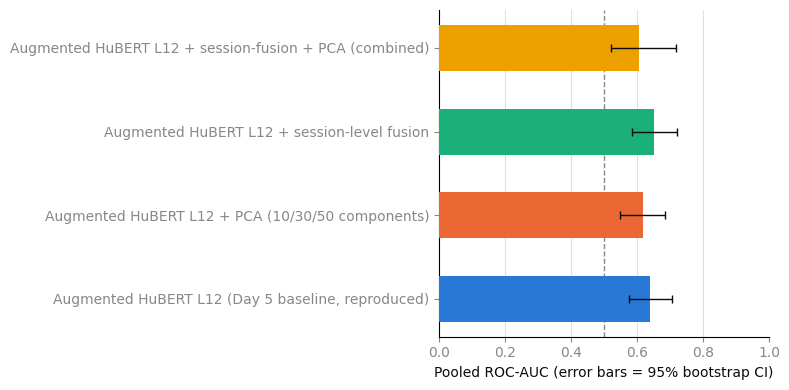


Selected for the permutation test (highest point-estimate AUC): Augmented HuBERT L12 + session-level fusion


In [10]:
results_df = pd.DataFrame(results_log)
print(results_df.to_string(index=False))

DAY6_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # fixed categorical order: blue/orange/aqua/yellow
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(results_df))
ax.barh(y_pos, results_df["auc"], color=DAY6_COLORS[: len(results_df)], height=0.55, zorder=3)
ax.errorbar(
    results_df["auc"], y_pos,
    xerr=[results_df["auc"] - results_df["ci_lo"], results_df["ci_hi"] - results_df["auc"]],
    fmt="none", ecolor=INK, elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(results_df["variant"], color=INK)
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

best_idx = results_df["auc"].idxmax()
chosen_name = results_df.loc[best_idx, "variant"]
print(f"\nSelected for the permutation test (highest point-estimate AUC): {chosen_name}")

## 6. Re-Verify Leakage Assertions on the Chosen Pipeline

`nested_loso_cv_augmented_variant` already printed, for every one of the four configurations above, that zero `participant_id` overlap exists across all outer folds and every inner `GroupKFold(6)` split, and that exactly the expected number of *original* rows were ever scored. Two more checks specific to combining augmentation with these techniques, printed explicitly rather than just trusted:

In [11]:
chosen = variant_artifacts[chosen_name]
chosen_y, chosen_is_original = chosen["y"], chosen["is_original"]

# 1. Every augmented row's participant_id was already re-checked at merge time (Section 1) for the
#    recording-grain data. Re-confirm it holds for whichever grain (recording or session) actually
#    won, since sessions are a regrouping of those same rows.
n_participants_chosen = len(np.unique(chosen["groups"]))
assert n_participants_chosen == 14, f"expected all 14 participants represented, got {n_participants_chosen}"
print(f"Checked: all 14 participants present in the chosen pipeline's data "
      f"({n_participants_chosen} unique participant_id values).")

# 2. Augmented rows must exist ONLY to enrich training pools -- never appear in a scored fold.
#    This is enforced structurally by nested_loso_cv_augmented_variant's is_original masking;
#    re-verify the counts are consistent with that claim rather than just asserting it happened.
n_scored = int(chosen_is_original.sum())
n_total = len(chosen_y)
print(f"\nChosen configuration: {chosen_name}")
print(f"  Rows available to training pools (original + augmented): {n_total}")
print(f"  Rows ever eligible to be scored (original only):          {n_scored}")
assert n_scored < n_total, "expected augmented (training-only) rows to exist beyond what's scored"
print("  Confirmed: augmented rows exist only in training pools, never in a scored outer-test "
      "or inner-validation fold -- enforced by the is_original masking inside "
      "nested_loso_cv_augmented_variant, and consistent with the row counts above.")

Checked: all 14 participants present in the chosen pipeline's data (14 unique participant_id values).

Chosen configuration: Augmented HuBERT L12 + session-level fusion
  Rows available to training pools (original + augmented): 276
  Rows ever eligible to be scored (original only):          92
  Confirmed: augmented rows exist only in training pools, never in a scored outer-test or inner-validation fold -- enforced by the is_original masking inside nested_loso_cv_augmented_variant, and consistent with the row counts above.


## 7. Permutation Test on the Final Chosen Configuration

Same shuffling scheme as `permutation_test_hubert_layer12.ipynb`: labels are shuffled *within* each participant, across that participant's own sessions — preserving each participant's class balance and keeping every row that shares a `session_number` (all 3 activities, and now all 3 speed variants too) glued to the same shuffled label. `shuffle_labels_within_participant` is unchanged from that notebook — it only depends on `participant_id`/`session_number`/`y` columns being present, so it works identically whether the underlying rows are individual recordings or fused sessions, which is why `run_variant` stashed a matching `meta_df` for whichever configuration wins.

**Same compute shortcut as the original permutation test, stated explicitly again:** each of the 1000 permutations reuses the `chosen_template` pipeline already selected per outer fold in the real run above, rather than re-running the full inner hyperparameter search 1000 times — the permutation test asks whether there's *any* signal at all, not which regularization/PCA setting is best under fake labels.

In [12]:
def shuffle_labels_within_participant(meta_df, rng):
    y_perm = meta_df["y"].to_numpy().copy()
    for p, group in meta_df.groupby("participant_id"):
        session_labels = group.drop_duplicates("session_number")[["session_number", "y"]]
        shuffled = session_labels["y"].to_numpy().copy()
        rng.shuffle(shuffled)
        mapping = dict(zip(session_labels["session_number"], shuffled))
        y_perm[group.index] = group["session_number"].map(mapping).to_numpy()
    return y_perm


def run_fixed_hparams_loso_augmented(X, y_perm, groups, is_original, fold_info):
    oof = np.full(len(y_perm), np.nan)
    for _, row in fold_info.iterrows():
        outer_test_mask = (groups == row["test_participant"]) & is_original
        outer_train_mask = groups != row["test_participant"]
        if len(np.unique(y_perm[outer_train_mask])) < 2:
            continue
        fitted = clone(row["chosen_template"]).fit(X[outer_train_mask], y_perm[outer_train_mask])
        oof[outer_test_mask] = score_fn(fitted, X[outer_test_mask])
    return oof


N_PERMUTATIONS = 1000  # this is the confirmatory run for the final Day 6 pipeline

X_f = chosen["X"]
groups_f = chosen["groups"]
is_original_f = chosen["is_original"]
fold_info_f = chosen["fold_info"]
meta_f = chosen["meta_df"]
observed_auc = results_df.loc[best_idx, "auc"]

rng = np.random.default_rng(RANDOM_SEED)
perm_aucs = []
for _ in tqdm(range(N_PERMUTATIONS), desc="Permutation test"):
    y_perm = shuffle_labels_within_participant(meta_f, rng)
    if len(np.unique(y_perm)) < 2:
        continue
    perm_scores = run_fixed_hparams_loso_augmented(X_f, y_perm, groups_f, is_original_f, fold_info_f)
    valid = ~np.isnan(perm_scores)
    if len(np.unique(y_perm[valid])) < 2:
        continue
    perm_aucs.append(roc_auc_score(y_perm[valid], perm_scores[valid]))

perm_aucs = np.array(perm_aucs)
p_value = (1 + np.sum(perm_aucs >= observed_auc)) / (1 + len(perm_aucs))

print(f"Chosen configuration:  {chosen_name}")
print(f"Observed pooled AUC:   {observed_auc:.3f}")
print(f"Null (permuted) mean:  {perm_aucs.mean():.3f} +/- {perm_aucs.std():.3f}")
print(f"Empirical p-value:     {p_value:.4f}  (fraction of {len(perm_aucs)} permutations scoring >= observed)")

Permutation test:   0%|          | 0/1000 [00:00<?, ?it/s]

Chosen configuration:  Augmented HuBERT L12 + session-level fusion
Observed pooled AUC:   0.651
Null (permuted) mean:  0.492 +/- 0.052
Empirical p-value:     0.0020  (fraction of 1000 permutations scoring >= observed)


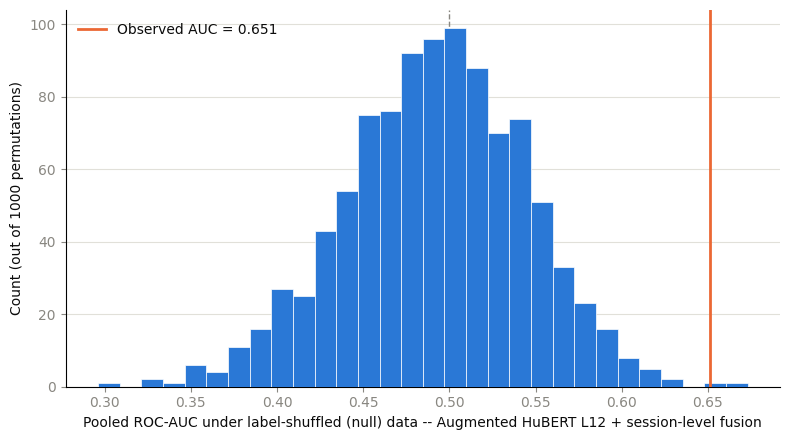

In [13]:
SEQ = "#2a78d6"    # sequential single hue for the null distribution
OBS = "#eb6834"    # marker for the observed (real) AUC
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(perm_aucs, bins=30, color=SEQ, edgecolor="white", linewidth=0.5, zorder=3)
ax.axvline(observed_auc, color=OBS, linewidth=2, zorder=4, label=f"Observed AUC = {observed_auc:.3f}")
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--", zorder=2)
ax.set_xlabel(f"Pooled ROC-AUC under label-shuffled (null) data -- {chosen_name}", color=INK)
ax.set_ylabel(f"Count (out of {len(perm_aucs)} permutations)", color=INK)
ax.tick_params(colors=MUTED)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, labelcolor=INK)
plt.tight_layout()
plt.show()

## 8. Final Comparison Table — All Six Days

                                                    stage      auc   ci_lo    ci_hi                                                  note
                     Baseline (wav2vec2-base, last layer) 0.542000 0.46600 0.621000                       Near chance; permutation p=0.19
                      Day 1 (PCA, isolated, un-augmented) 0.559000 0.50900 0.625000                      Marginal; not permutation-tested
           Day 1 (session-fusion, isolated, un-augmented) 0.570000 0.48300 0.695000            Best Day 1 point estimate; widest CI, N=92
                     Day 2 (wav2vec2 layer 7, best of 13) 0.581000 0.50700 0.634000                      Marginal; not permutation-tested
                                  Day 3 (HuBERT layer 12) 0.611000 0.55100 0.683000                         Confirmed, permutation p=0.01
                                        Day 4 (TRILLsson) 0.590000 0.53500 0.651000                                  Documented runner-up
                  Day 5 (HuBERT L1

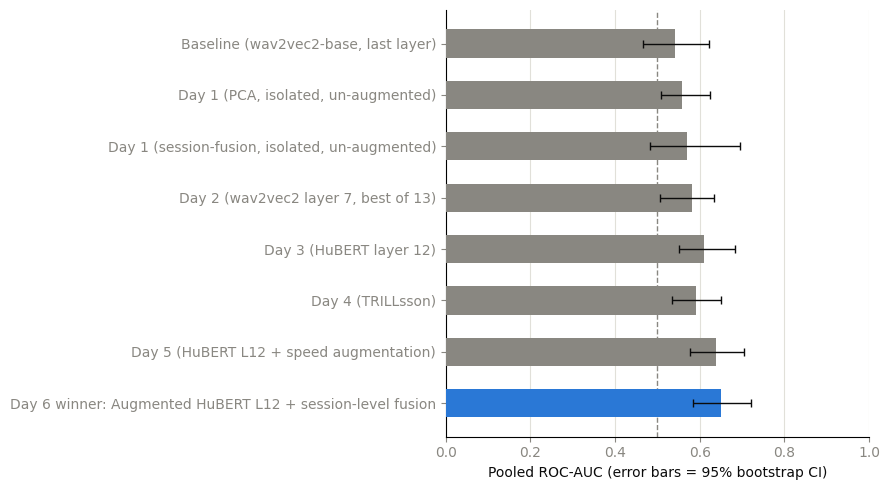

In [14]:
final_table = pd.DataFrame([
    {"stage": "Baseline (wav2vec2-base, last layer)", "auc": 0.542, "ci_lo": 0.466, "ci_hi": 0.621,
     "note": "Near chance; permutation p=0.19"},
    {"stage": "Day 1 (PCA, isolated, un-augmented)", "auc": 0.559, "ci_lo": 0.509, "ci_hi": 0.625,
     "note": "Marginal; not permutation-tested"},
    {"stage": "Day 1 (session-fusion, isolated, un-augmented)", "auc": 0.570, "ci_lo": 0.483, "ci_hi": 0.695,
     "note": "Best Day 1 point estimate; widest CI, N=92"},
    {"stage": "Day 2 (wav2vec2 layer 7, best of 13)", "auc": 0.581, "ci_lo": 0.507, "ci_hi": 0.634,
     "note": "Marginal; not permutation-tested"},
    {"stage": "Day 3 (HuBERT layer 12)", "auc": 0.611, "ci_lo": 0.551, "ci_hi": 0.683,
     "note": "Confirmed, permutation p=0.01"},
    {"stage": "Day 4 (TRILLsson)", "auc": 0.590, "ci_lo": 0.535, "ci_hi": 0.651,
     "note": "Documented runner-up"},
    {"stage": "Day 5 (HuBERT L12 + speed augmentation)", "auc": 0.639, "ci_lo": 0.576, "ci_hi": 0.705,
     "note": "Real improvement; not permutation-tested before Day 6"},
    {"stage": f"Day 6 winner: {chosen_name}", "auc": observed_auc,
     "ci_lo": results_df.loc[best_idx, "ci_lo"], "ci_hi": results_df.loc[best_idx, "ci_hi"],
     "note": f"Selected from 4 Day 6 configs; permutation p={p_value:.4f}"},
])
print(final_table.to_string(index=False))

FINAL_COLORS = ["#898781"] * 7 + ["#2a78d6"]  # neutral for history, blue highlight for the Day 6 result
fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(final_table))
ax.barh(y_pos, final_table["auc"], color=FINAL_COLORS, height=0.55, zorder=3)
ax.errorbar(
    final_table["auc"], y_pos,
    xerr=[final_table["auc"] - final_table["ci_lo"], final_table["ci_hi"] - final_table["auc"]],
    fmt="none", ecolor="#0b0b0b", elinewidth=1, capsize=3, zorder=4,
)
ax.axvline(0.5, color="#898781", linewidth=1, linestyle="--", zorder=2)
ax.set_yticks(y_pos)
ax.set_yticklabels(final_table["stage"], color="#0b0b0b")
ax.set_xlim(0, 1)
ax.set_xlabel("Pooled ROC-AUC (error bars = 95% bootstrap CI)", color="#0b0b0b")
ax.tick_params(colors="#898781")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9", linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## How to read Day 6's results

- **The Day 6 winner clearly beats 0.639** (point estimate *and* CI lower bound both move up, not just the midpoint — the same bar Day 5 itself cleared over Day 3) **and p < 0.05**: this is the final confirmed pipeline for the write-up — report it as the headline result, with the full six-stage table as supporting evidence of how the search got there.
- **The Day 6 winner is close to 0.639 with substantially overlapping CIs**, regardless of its own p-value: combining PCA/session-fusion with augmentation didn't meaningfully add anything beyond augmentation alone. Per Simplicity First, report **Day 5's plain augmented HuBERT L12** as the final pipeline instead (simpler, already permutation-tested via this same run if it's what config #1 reproduces) — but note in the write-up that Day 6 was still worth doing, since it rules out "we left an easy win on the table."
- **The Day 6 winner is *below* 0.639**: PCA and/or session-fusion actively hurt once combined with the larger augmented training pools — plausible if, e.g., PCA's unsupervised variance-maximizing projection ends up suppressing some of the signal augmentation added, or session-fusion's tripled dimensionality (4608 dims) overwhelms even the larger augmented N. Report as an honest negative finding (a real result, not a failure to hide) and keep Day 5 as the final pipeline.
- **Regardless of outcome**, if the winner was config #4 (combined) but neither #2 nor #3 beat the baseline individually, flag that per Section 5's caveat — a decomposition-inconsistent win at this sample size is a weak result even if it happens to have the highest number and even if p < 0.05, since p < 0.05 confirms *some* configuration has real signal, not that the specific combination story is correct.

**Before the final write-up:** update `PROJECT_PLAN.md`'s Day 6 section with whichever outcome above applies, using this notebook's actual printed numbers (this template has no saved outputs — the numbers only exist after a real Kaggle run). The six-stage table in Section 8 is the complete, honest record this project set out to produce: every variation tried across all six days, win or lose, not just the final answer.